# AZIZ RAHMAD ARIFIN 5054251002

# Sequential Pattern Mining — Online Retail (PrefixSpan)


Alur: Import data → Eksplorasi & pembersihan → Penyusunan sequence per pelanggan → PrefixSpan → Evaluasi pola → Laporan.

In [1]:
import pandas as pd
import numpy as np
import requests
import math
import time
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# 1. Unduh dan Import Dataset

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"

response = requests.get(url, timeout=180)
response.raise_for_status()

with open("Online_Retail.xlsx", "wb") as f:
    f.write(response.content)

In [3]:
df = pd.read_excel("Online_Retail.xlsx")

print("=" * 4, "5 Baris Pertama", "=" * 4)
display(df.head())

print("=" * 4, "Ukuran Dataset (baris, kolom)", "=" * 4)
print(df.shape)

print("=" * 4, "Informasi Dataset", "=" * 4)
df.info()

==== 5 Baris Pertama ====


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


==== Ukuran Dataset (baris, kolom) ====
(541909, 8)
==== Informasi Dataset ====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


# 2. Eksplorasi dan Pembersihan Data

Kolom yang relevan untuk pola berurutan:
- `CustomerID` : penentu satu sequence (satu pelanggan = satu sequence)
- `InvoiceNo`  : penentu satu itemset (item dalam satu invoice = satu itemset)
- `InvoiceDate`: penentu urutan waktu antar itemset
- `Description`: item yang dibeli (StockCode dipakai hanya untuk menyaring baris non-produk)

In [4]:
print("Persentase missing value per kolom (%)")
display((df.isna().sum() / len(df) * 100).round(2))

Persentase missing value per kolom (%)


,0
InvoiceNo,0.00
StockCode,0.00
Description,0.27
Quantity,0.00
InvoiceDate,0.00
UnitPrice,0.00
CustomerID,24.93
Country,0.00


In [5]:
# Simpan statistik sebelum pembersihan
sebelum = {
    "Jumlah baris": len(df),
    "Jumlah invoice": df["InvoiceNo"].nunique(),
    "Jumlah pelanggan": df["CustomerID"].nunique(),
}

df_clean = df.copy()

# 1) Hapus Description kosong (dropna dengan subset -> benar-benar menghapus baris)
df_clean = df_clean.dropna(subset=["Description"])
df_clean["Description"] = df_clean["Description"].astype(str).str.strip().str.upper()
df_clean = df_clean[df_clean["Description"] != ""]

# 2) Hapus transaksi dibatalkan (InvoiceNo diawali "C")
df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str)
df_clean = df_clean[~df_clean["InvoiceNo"].str.startswith("C")]

# 3) Hapus Quantity negatif / nol
df_clean = df_clean[df_clean["Quantity"] > 0]

# 4) Hapus CustomerID kosong (sequence disusun per pelanggan)
df_clean = df_clean.dropna(subset=["CustomerID"])
df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

print("Sisa baris setelah 4 langkah wajib:", f"{len(df_clean):,}")

Sisa baris setelah 4 langkah wajib: 397,924


**Langkah tambahan (opsional, bisa dimatikan):** dataset ini memuat baris non-produk seperti `POSTAGE`, `Manual`, `DOTCOM POSTAGE`, `BANK CHARGES`. Baris ini muncul di hampir semua transaksi sehingga akan mendominasi pola. Ubah `HAPUS_NON_PRODUK = False` jika ingin mengikuti ketentuan praktikum secara ketat.

In [6]:
HAPUS_NON_PRODUK = True

kode_non_produk = ["POST", "D", "M", "DOT", "CRUK", "C2", "BANK CHARGES",
                   "AMAZONFEE", "S", "B", "PADS", "ADJUST", "ADJUST2"]

if HAPUS_NON_PRODUK:
    mask = df_clean["StockCode"].astype(str).str.upper().isin(kode_non_produk)
    print(f"Baris non-produk dihapus: {mask.sum():,}")
    df_clean = df_clean[~mask]

sesudah = {
    "Jumlah baris": len(df_clean),
    "Jumlah invoice": df_clean["InvoiceNo"].nunique(),
    "Jumlah pelanggan": df_clean["CustomerID"].nunique(),
}

ringkasan = pd.DataFrame({"Sebelum": sebelum, "Sesudah": sesudah})
ringkasan["Selisih"] = ringkasan["Sebelum"] - ringkasan["Sesudah"]
print("--- Hasil Pembersihan Data ---")
display(ringkasan.style.format("{:,.0f}"))

Baris non-produk dihapus: 1,554
--- Hasil Pembersihan Data ---


,Sebelum,Sesudah,Selisih
Jumlah baris,"541,909","396,370","145,539"
Jumlah invoice,"25,900","18,405","7,495"
Jumlah pelanggan,"4,372","4,335",37


In [7]:
# Pastikan tidak ada sisa data kotor
print("Missing Description :", df_clean["Description"].isna().sum())
print("Missing CustomerID  :", df_clean["CustomerID"].isna().sum())
print("Invoice awalan C    :", df_clean["InvoiceNo"].str.startswith("C").sum())
print("Quantity <= 0       :", (df_clean["Quantity"] <= 0).sum())

Missing Description : 0
Missing CustomerID  : 0
Invoice awalan C    : 0
Quantity <= 0       : 0


# 3. Persiapan Data untuk Sequential Pattern Mining

1. Urutkan berdasarkan `CustomerID` dan `InvoiceDate`.
2. Item dalam satu invoice digabung menjadi **satu itemset**.
3. Itemset-itemset milik satu pelanggan disusun urut waktu menjadi **satu sequence**.

In [8]:
invoice_df = (
    df_clean.groupby(["CustomerID", "InvoiceNo"])
    .agg(InvoiceDate=("InvoiceDate", "min"),
         Items=("Description", lambda s: frozenset(s)))
    .reset_index()
    .sort_values(["CustomerID", "InvoiceDate", "InvoiceNo"])
)

print("Jumlah itemset (invoice) :", f"{len(invoice_df):,}")
display(invoice_df.head())

Jumlah itemset (invoice) : 18,405


,CustomerID,InvoiceNo,InvoiceDate,Items
0,12346,541431,2011-01-18 10:01:00,(MEDIUM CERAMIC TOP STORAGE JAR)
1,12347,537626,2010-12-07 14:57:00,"(ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKEL..."
2,12347,542237,2011-01-26 14:30:00,"(ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKEL..."
3,12347,549222,2011-04-07 10:43:00,"(ICE CREAM SUNDAE LIP GLOSS, AIRLINE BAG VINTA..."
4,12347,556201,2011-06-09 13:01:00,"(TRIPLE HOOK ANTIQUE IVORY ROSE, REGENCY SUGAR..."


In [9]:
# Satu pelanggan = satu sequence = list itemset yang urut waktu
seq_series = invoice_df.groupby("CustomerID")["Items"].apply(list)

# Bentuk list of list (itemset diurutkan abjad agar rapi) untuk dokumentasi / ekspor ke SPMF
sequences_list = [[sorted(itemset) for itemset in seq] for seq in seq_series]

# Bentuk list of set untuk proses mining (pengecekan item lebih cepat)
sequences = [[set(itemset) for itemset in seq] for seq in seq_series]

n_cust = len(sequences)
print("Jumlah sequence (pelanggan):", f"{n_cust:,}")

print("\nContoh sequence pelanggan pertama (3 itemset pertama):")
for i, itemset in enumerate(sequences_list[0][:3], start=1):
    print(f"  Itemset {i}: {itemset[:5]}{' ...' if len(itemset) > 5 else ''}")

Jumlah sequence (pelanggan): 4,335

Contoh sequence pelanggan pertama (3 itemset pertama):
  Itemset 1: ['MEDIUM CERAMIC TOP STORAGE JAR']


count    4335.00
mean        4.25
std         7.64
min         1.00
25%         1.00
50%         2.00
75%         5.00
max       206.00
dtype: float64

Pelanggan dengan hanya 1 invoice: 1,506 (34.7%)


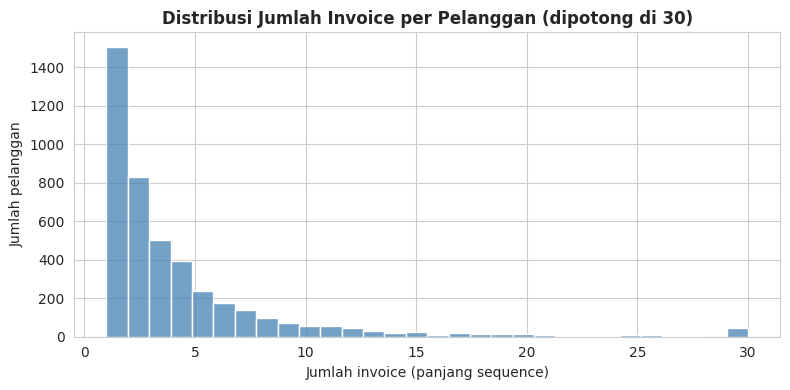

In [10]:
# Distribusi panjang sequence (jumlah invoice per pelanggan)
panjang = pd.Series([len(s) for s in sequences])
print(panjang.describe().round(2))
print(f"\nPelanggan dengan hanya 1 invoice: {(panjang == 1).sum():,} ({(panjang == 1).mean():.1%})")

plt.figure(figsize=(8, 4))
sns.histplot(panjang.clip(upper=30), bins=30, color="steelblue")
plt.title("Distribusi Jumlah Invoice per Pelanggan (dipotong di 30)", fontweight="bold")
plt.xlabel("Jumlah invoice (panjang sequence)")
plt.ylabel("Jumlah pelanggan")
plt.tight_layout()
plt.show()

# 4. Penerapan Algoritma PrefixSpan

Library `prefixspan` hanya menerima sequence yang elemennya item tunggal, sehingga batas antar-invoice hilang. Karena itu PrefixSpan di sini diimplementasikan langsung dan bekerja pada sequence **itemset**:

- Pola berbentuk `⟨a → b → c⟩`: `a` dibeli di suatu invoice, `b` di invoice **yang lebih akhir**, `c` di invoice yang lebih akhir lagi.
- **Support** = proporsi pelanggan yang memiliki pola tersebut sebagai subsequence (relatif terhadap seluruh pelanggan).
- Proyeksi database: setelah item cocok di invoice ke-*k*, pencarian item berikutnya dimulai dari invoice ke-*(k+1)* (pencocokan paling awal), sehingga item dalam satu invoice tidak dihitung sebagai urutan.
- `max_len` membatasi panjang pola agar waktu komputasi terkendali.

In [11]:
def prefixspan_itemset(db, min_count, max_len=3):
    """PrefixSpan untuk sequence of itemsets, elemen pola berupa item tunggal.
    Mengembalikan list (pola: tuple, jumlah_pelanggan: int)."""
    hasil = []

    def mine(prefix, projected):
        cnt = Counter()
        for sid, start in projected:
            muncul = set()
            for itemset in db[sid][start:]:
                muncul |= itemset
            cnt.update(muncul)

        for item, c in cnt.items():
            if c < min_count:
                continue
            pola = prefix + (item,)
            hasil.append((pola, c))
            if len(pola) < max_len:
                proj_baru = []
                for sid, start in projected:
                    seq = db[sid]
                    for k in range(start, len(seq)):
                        if item in seq[k]:
                            proj_baru.append((sid, k + 1))
                            break
                mine(pola, proj_baru)

    mine((), [(i, 0) for i in range(len(db))])
    return hasil


MIN_SUP = 0.01      # titik awal sesuai ketentuan
MAX_LEN = 3

min_count = math.ceil(MIN_SUP * n_cust)
t0 = time.time()
patterns = prefixspan_itemset(sequences, min_count, MAX_LEN)
print(f"min_support = {MIN_SUP} -> minimal {min_count} pelanggan")
print(f"Jumlah pola ditemukan : {len(patterns):,}  (waktu {time.time() - t0:.1f} detik)")
print("Jumlah pola per panjang:", dict(sorted(Counter(len(p) for p, _ in patterns).items())))

min_support = 0.01 -> minimal 44 pelanggan
Jumlah pola ditemukan : 34,674  (waktu 75.8 detik)
Jumlah pola per panjang: {1: 1761, 2: 15666, 3: 17247}


### Penyesuaian minimum support
Bandingkan beberapa nilai `min_support` untuk menilai apakah pola terlalu banyak / terlalu sedikit.

,min_support,min_count (pelanggan),Total pola,Panjang 1,Panjang 2,Panjang 3,Waktu (dtk)
0,0.01,44,34674,1761,15666,17247,76.6
1,0.02,87,2965,1044,1505,416,18.8
2,0.03,131,944,655,280,9,9.9
3,0.05,217,273,264,8,1,3.4


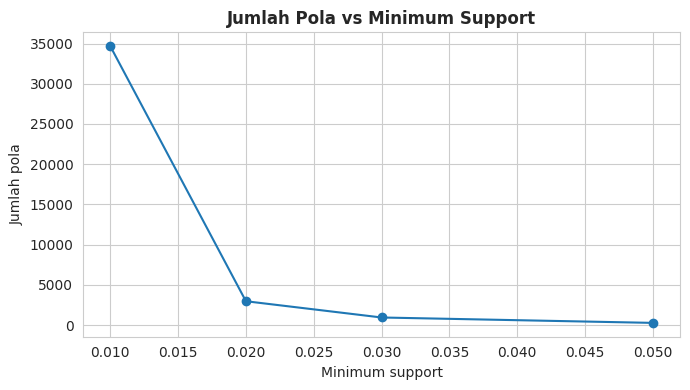

In [12]:
uji = []
for ms in [0.01, 0.02, 0.03, 0.05]:
    mc = math.ceil(ms * n_cust)
    t0 = time.time()
    hasil = prefixspan_itemset(sequences, mc, MAX_LEN)
    per_len = Counter(len(p) for p, _ in hasil)
    uji.append({
        "min_support": ms,
        "min_count (pelanggan)": mc,
        "Total pola": len(hasil),
        "Panjang 1": per_len.get(1, 0),
        "Panjang 2": per_len.get(2, 0),
        "Panjang 3": per_len.get(3, 0),
        "Waktu (dtk)": round(time.time() - t0, 1),
    })

uji_df = pd.DataFrame(uji)
display(uji_df)

plt.figure(figsize=(7, 4))
plt.plot(uji_df["min_support"], uji_df["Total pola"], marker="o", color="tab:blue")
plt.title("Jumlah Pola vs Minimum Support", fontweight="bold")
plt.xlabel("Minimum support")
plt.ylabel("Jumlah pola")
plt.tight_layout()
plt.show()

### Keputusan parameter
Pilih `MIN_SUP_FINAL` berdasarkan tabel di atas. Jika dengan 0.01 pola masih wajar (puluhan sampai beberapa ratus pola berurutan, mudah dianalisis), pertahankan 0.01. Jika terlalu banyak, naikkan ke 0.02 atau 0.03; jika terlalu sedikit, turunkan.

**Alasan pemilihan:** *(isi setelah melihat tabel — sebutkan jumlah pola, kemudahan analisis, dan dampak terhadap panjang pola)*

In [13]:
MIN_SUP_FINAL = 0.03  # <- sesuaikan setelah melihat tabel di atas

min_count = math.ceil(MIN_SUP_FINAL * n_cust)
patterns = prefixspan_itemset(sequences, min_count, MAX_LEN)
print(f"Dipakai min_support = {MIN_SUP_FINAL} ({min_count} pelanggan), total pola = {len(patterns):,}")

Dipakai min_support = 0.03 (131 pelanggan), total pola = 944


**Alasan pemilihan:** `min_support = 0.03` (minimal 131 dari 4.335 pelanggan) dengan `max_len = 3`.

- Pada 0.01 dihasilkan **34.674 pola** (butuh ±76 detik) — terlalu banyak untuk dianalisis dan kebanyakan hanya didukung 44–100 pelanggan.
- Pada 0.02 masih ada **2.965 pola**, juga terlalu banyak.
- Pada 0.05 hanya tersisa **273 pola**, dan pola berurutan panjang 2 cuma 8 buah — terlalu sedikit untuk melihat variasi urutan antar produk.
- Pada 0.03 dihasilkan **944 pola**, terdiri dari 655 item tunggal dan **289 pola berurutan** (280 berpanjang 2 dan 9 berpanjang 3). Jumlah ini cukup untuk dianalisis dan masih memuat pola panjang 3.

# 5. Evaluasi Pola Berurutan

Untuk pola `⟨a₁ → … → aₙ⟩` dengan n ≥ 2, dihitung aturan berurutan `⟨a₁ … aₙ₋₁⟩ ⟹ aₙ`:

- **Support** = jumlah pelanggan dengan pola / total pelanggan
- **Confidence** = support(pola) / support(prefix) → peluang pelanggan yang sudah membeli prefix akan kemudian membeli item terakhir
- **Lift** (tambahan) = confidence / support(item terakhir) → lift > 1 berarti urutan ini lebih sering terjadi dari kebetulan

In [14]:
def bangun_tabel(patterns, n_cust):
    sup = {p: c for p, c in patterns}
    baris = []
    for p, c in patterns:
        conf = lift = np.nan
        if len(p) > 1:
            conf = c / sup[p[:-1]]
            lift = conf / (sup[(p[-1],)] / n_cust)
        baris.append({
            "Pola": " → ".join(p),
            "Pola_wrap": " →\n".join(p),
            "Panjang": len(p),
            "Jml_Pelanggan": c,
            "Support": c / n_cust,
            "Confidence": conf,
            "Lift": lift,
            "Ada_Pengulangan": len(set(p)) < len(p),
        })
    return pd.DataFrame(baris)

pola_df = bangun_tabel(patterns, n_cust)
seq_df = (pola_df[pola_df["Panjang"] >= 2]
          .sort_values(["Support", "Confidence"], ascending=False)
          .reset_index(drop=True))

print(f"Pola berurutan (panjang >= 2): {len(seq_df):,}")
print(f"  - di antaranya pengulangan item yang sama (mis. A → A): {seq_df['Ada_Pengulangan'].sum():,}")
print(f"  - antar item berbeda: {(~seq_df['Ada_Pengulangan']).sum():,}")

pd.set_option("display.max_colwidth", 110)
display(seq_df[["Pola", "Panjang", "Jml_Pelanggan", "Support", "Confidence", "Lift"]].head(20))

Pola berurutan (panjang >= 2): 289
  - di antaranya pengulangan item yang sama (mis. A → A): 67
  - antar item berbeda: 222


,Pola,Panjang,Jml_Pelanggan,Support,Confidence,Lift
0,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,2,405,0.093426,0.473131,2.396054
1,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,2,330,0.076125,0.374574,1.843110
2,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,2,312,0.071972,0.491339,3.354256
3,ASSORTED COLOUR BIRD ORNAMENT → ASSORTED COLOUR BIRD ORNAMENT,2,291,0.067128,0.429204,2.744244
4,PARTY BUNTING → PARTY BUNTING,2,280,0.064591,0.395480,2.421479
5,LUNCH BAG RED RETROSPOT → LUNCH BAG RED RETROSPOT,2,276,0.063668,0.518797,4.227415
6,LUNCH BAG BLACK SKULL. → LUNCH BAG BLACK SKULL.,2,229,0.052826,0.500000,4.732533
7,SET OF 3 CAKE TINS PANTRY DESIGN → SET OF 3 CAKE TINS PANTRY DESIGN,2,225,0.051903,0.351562,2.381287
8,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,3,222,0.051211,0.548148,2.775961
9,LUNCH BAG RED RETROSPOT → LUNCH BAG BLACK SKULL.,2,212,0.048904,0.398496,3.771793


### Tiga pola terbaik berdasarkan support tertinggi

In [15]:
top3 = seq_df.head(3).copy()
display(top3[["Pola", "Jml_Pelanggan", "Support", "Confidence", "Lift"]])

for i, row in top3.iterrows():
    items = row["Pola"].split(" → ")
    print(f"\nPola {i + 1}: {row['Pola']}")
    print(f"  - Support    : {row['Support']:.4f}  ({row['Jml_Pelanggan']} dari {n_cust:,} pelanggan)")
    print(f"  - Confidence : {row['Confidence']:.4f}")
    print(f"  - Lift       : {row['Lift']:.2f}")
    print(f"  Interpretasi: {row['Support']:.1%} pelanggan membeli urutan ini. "
          f"Dari pelanggan yang sudah membeli [{' → '.join(items[:-1])}], "
          f"{row['Confidence']:.1%} kemudian membeli [{items[-1]}] pada transaksi berikutnya.")

,Pola,Jml_Pelanggan,Support,Confidence,Lift
0,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,405,0.093426,0.473131,2.396054
1,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,330,0.076125,0.374574,1.843110
2,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,312,0.071972,0.491339,3.354256



Pola 1: WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER
  - Support    : 0.0934  (405 dari 4,335 pelanggan)
  - Confidence : 0.4731
  - Lift       : 2.40
  Interpretasi: 9.3% pelanggan membeli urutan ini. Dari pelanggan yang sudah membeli [WHITE HANGING HEART T-LIGHT HOLDER], 47.3% kemudian membeli [WHITE HANGING HEART T-LIGHT HOLDER] pada transaksi berikutnya.

Pola 2: REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER
  - Support    : 0.0761  (330 dari 4,335 pelanggan)
  - Confidence : 0.3746
  - Lift       : 1.84
  Interpretasi: 7.6% pelanggan membeli urutan ini. Dari pelanggan yang sudah membeli [REGENCY CAKESTAND 3 TIER], 37.5% kemudian membeli [REGENCY CAKESTAND 3 TIER] pada transaksi berikutnya.

Pola 3: JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT
  - Support    : 0.0720  (312 dari 4,335 pelanggan)
  - Confidence : 0.4913
  - Lift       : 3.35
  Interpretasi: 7.2% pelanggan membeli urutan ini. Dari pelanggan yang sudah membeli [JUMBO BAG RED RETRO

In [16]:
# Pelengkap: tiga pola terbaik yang melibatkan item BERBEDA (bukan sekadar pembelian ulang)
top3_beda = seq_df[~seq_df["Ada_Pengulangan"]].head(3)
display(top3_beda[["Pola", "Jml_Pelanggan", "Support", "Confidence", "Lift"]])

,Pola,Jml_Pelanggan,Support,Confidence,Lift
9,LUNCH BAG RED RETROSPOT → LUNCH BAG BLACK SKULL.,212,0.048904,0.398496,3.771793
10,LUNCH BAG CARS BLUE → LUNCH BAG RED RETROSPOT,209,0.048212,0.436326,3.555398
11,LUNCH BAG BLACK SKULL. → LUNCH BAG RED RETROSPOT,208,0.047982,0.454148,3.700627


### Verifikasi manual
Hitung ulang support salah satu pola secara brute force untuk memastikan implementasi benar.

In [17]:
def hitung_support_manual(pola, db):
    total = 0
    for seq in db:
        idx = 0
        for itemset in seq:
            if pola[idx] in itemset:
                idx += 1
                if idx == len(pola):
                    total += 1
                    break
    return total

pola_uji = tuple(seq_df.loc[0, "Pola"].split(" → "))
manual = hitung_support_manual(pola_uji, sequences)
print("Pola uji          :", " → ".join(pola_uji))
print("Hitungan PrefixSpan:", seq_df.loc[0, "Jml_Pelanggan"])
print("Hitungan manual    :", manual)
print("Cocok              :", manual == seq_df.loc[0, "Jml_Pelanggan"])

Pola uji          : WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER
Hitungan PrefixSpan: 405
Hitungan manual    : 405
Cocok              : True


### Visualisasi

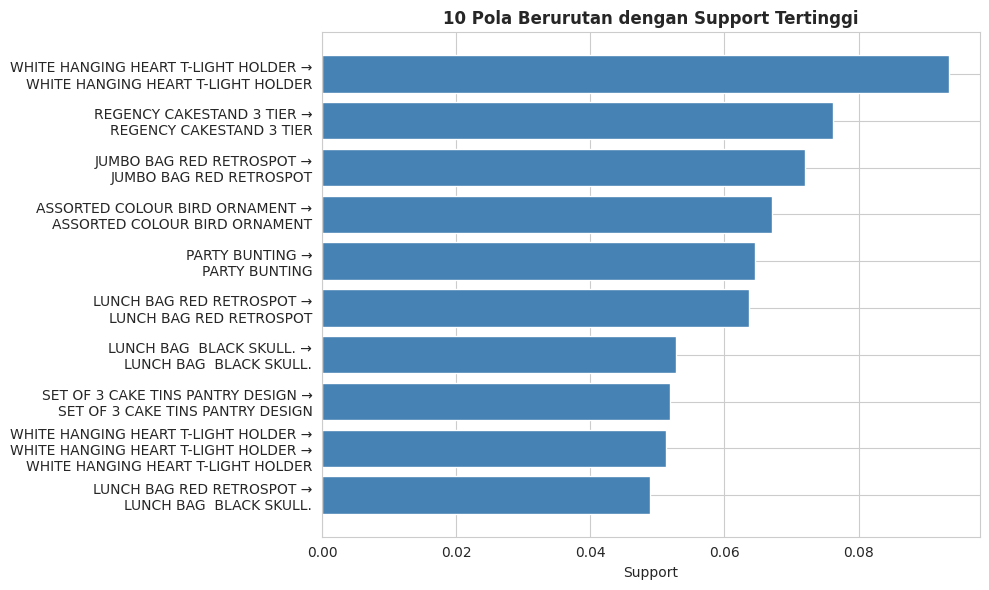

In [18]:
# 1) Top 10 pola berdasarkan support
top10 = seq_df.head(10).iloc[::-1]
plt.figure(figsize=(10, 6))
plt.barh(top10["Pola_wrap"], top10["Support"], color="steelblue")
plt.title("10 Pola Berurutan dengan Support Tertinggi", fontweight="bold")
plt.xlabel("Support")
plt.tight_layout()
plt.show()

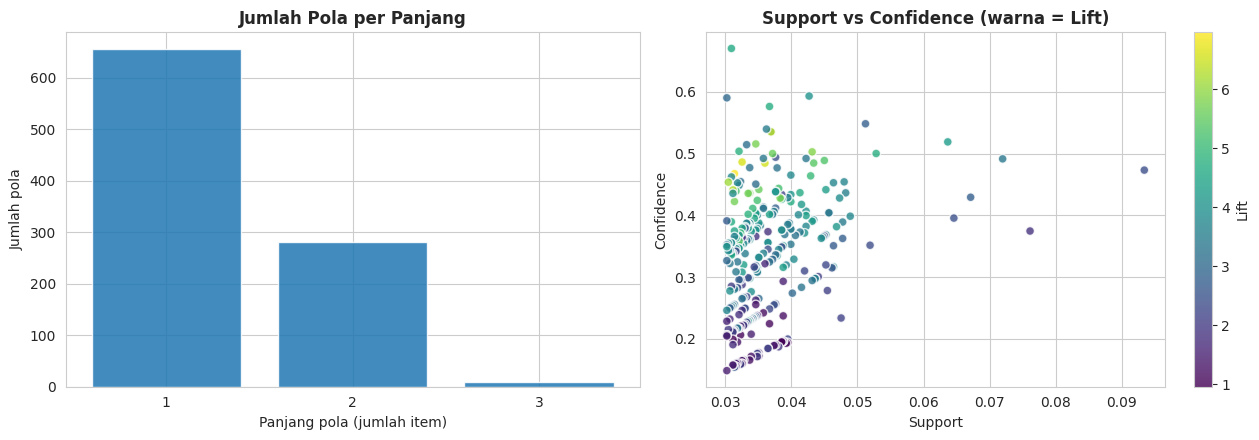

In [19]:
# 2) Jumlah pola per panjang & sebaran support vs confidence
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

per_len = pola_df["Panjang"].value_counts().sort_index()
axes[0].bar(per_len.index.astype(str), per_len.values, color="tab:blue", alpha=0.85)
axes[0].set_title("Jumlah Pola per Panjang", fontweight="bold")
axes[0].set_xlabel("Panjang pola (jumlah item)")
axes[0].set_ylabel("Jumlah pola")

sc = axes[1].scatter(seq_df["Support"], seq_df["Confidence"], c=seq_df["Lift"],
                     cmap="viridis", s=40, alpha=0.8, edgecolors="w")
plt.colorbar(sc, ax=axes[1], label="Lift")
axes[1].set_title("Support vs Confidence (warna = Lift)", fontweight="bold")
axes[1].set_xlabel("Support")
axes[1].set_ylabel("Confidence")

plt.tight_layout()
plt.show()

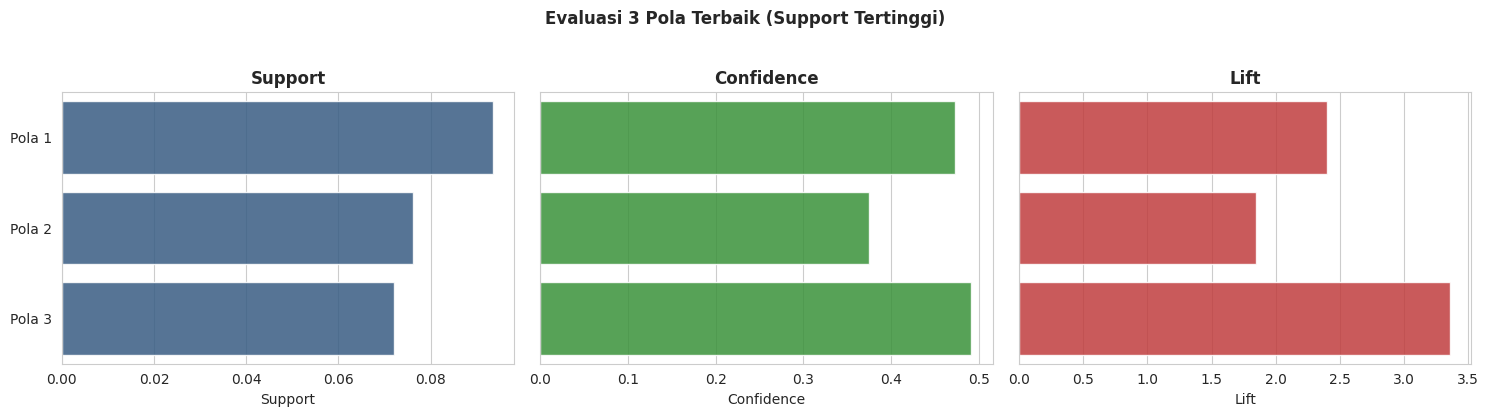

In [20]:
# 3) Metrik tiga pola terbaik
t = top3.copy()
t["Nama"] = [f"Pola {i + 1}" for i in range(len(t))]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
warna = ["#2b5c8f", "#2ca02c", "#d62728"]
for ax, metrik, w in zip(axes, ["Support", "Confidence", "Lift"], warna):
    sns.barplot(x=metrik, y="Nama", data=t, ax=ax, color=w, alpha=0.85)
    ax.set_title(metrik, fontweight="bold")
axes[0].set_ylabel("")
plt.suptitle("Evaluasi 3 Pola Terbaik (Support Tertinggi)", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

# 6. Laporan Singkat

## 6.1 Hasil Eksplorasi dan Pembersihan Data
Dataset awal berisi 541.909 baris dan 8 kolom. Missing value terbesar ada di `CustomerID` (24,93%), lalu `Description` (0,27%). Baris tanpa `CustomerID` harus dibuang karena sequence disusun per pelanggan.

Pembersihan yang dilakukan: hapus `Description` kosong, hapus invoice batal (awalan "C"), hapus `Quantity` ≤ 0, hapus `CustomerID` kosong. Setelah keempat langkah ini tersisa 397.924 baris. Saya juga menghapus 1.554 baris non-produk (POSTAGE, Manual, BANK CHARGES, dll.) karena muncul di banyak transaksi dan bukan barang yang dibeli.

| | Sebelum | Sesudah | Selisih |
|---|---|---|---|
| Jumlah baris | 541.909 | 396.370 | 145.539 |
| Jumlah invoice | 25.900 | 18.405 | 7.495 |
| Jumlah pelanggan | 4.372 | 4.335 | 37 |

Hasil akhirnya 4.335 sequence (satu per pelanggan) dengan 18.405 itemset. Rata-rata pelanggan punya 4,25 invoice (median 2, maksimum 206), dan 1.506 pelanggan (34,7%) hanya punya satu invoice sehingga tidak bisa membentuk pola berurutan.

## 6.2 Pola Berurutan dan Evaluasi
Algoritma PrefixSpan dengan `min_support = 0.03`, `max_len = 3`, menghasilkan 944 pola, 289 di antaranya pola berurutan (panjang ≥ 2). Dari 289 pola itu, 67 berupa pembelian ulang item yang sama (A → A) dan 222 berupa urutan item berbeda.

**Tiga pola terbaik berdasarkan support**

| No | Pola | Support | Confidence | Lift |
|---|---|---|---|---|
| 1 | WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER | 0,0934 (405 pelanggan) | 0,4731 | 2,40 |
| 2 | REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER | 0,0761 (330 pelanggan) | 0,3746 | 1,84 |
| 3 | JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT | 0,0720 (312 pelanggan) | 0,4913 | 3,35 |

**Interpretasi bisnis**
1. **White Hanging Heart T-Light Holder:** 9,3% pelanggan membeli produk ini lalu membelinya lagi di transaksi berikutnya. Dari pelanggan yang pernah membelinya, 47,3% membeli lagi. Ini produk andalan dengan pembelian ulang tinggi, cocok untuk pengingat restock atau diskon pembelian berikutnya.
2. **Regency Cakestand 3 Tier:** 37,5% pembeli membeli lagi. Pembelian ulang terjadi namun lebih rendah, kemungkinan karena produk tahan lama sehingga cukup dibeli sekali oleh pelanggan ritel.
3. **Jumbo Bag Red Retrospot:** confidence 49,1% (hampir separuh pembeli kembali membeli) dan lift 3,35, tertinggi di antara ketiganya. Pembelian ulang di sini jauh di atas kebetulan, jadi produk ini kuat untuk paket langganan atau bundling.

Ketiga pola teratas semuanya pembelian ulang item yang sama. Untuk melihat produk lanjutan, pola berbeda terbaik adalah LUNCH BAG RED RETROSPOT → LUNCH BAG BLACK SKULL (support 0,0489, confidence 0,3985, lift 3,77). Pelanggan yang membeli satu motif tas makan siang cenderung menambah motif lain pada kunjungan berikutnya, sehingga toko bisa merekomendasikan motif lain dalam seri yang sama.

Semua lift > 1, artinya urutan-urutan ini muncul lebih sering daripada yang diharapkan secara kebetulan. Hasil PrefixSpan juga sudah diverifikasi dengan hitungan manual (405 = 405).

## 6.3 Kesimpulan
Pola pembelian berurutan di dataset ini didominasi oleh **pembelian ulang produk yang sama** (A → A), dengan confidence 37–49% dan lift 1,8–3,4. Ini wajar karena banyak pelanggan Online Retail adalah pembeli grosir yang rutin memesan ulang. Selain itu ada pola **produk lanjutan dalam satu seri** (misalnya antar motif Lunch Bag), dengan lift tinggi (3,5–4,7).

Support tertinggi hanya 9,3%, karena produknya ribuan dan pelanggan menyebar ke banyak barang. Keterbatasannya: 34,7% pelanggan hanya punya satu invoice sehingga tidak berkontribusi pada pola berurutan; panjang pola dibatasi 3; data hanya satu toko di Inggris selama 13 bulan; dan baris tanpa CustomerID (±25%) tidak bisa dipakai.

Secara praktis, hasil ini bisa dipakai untuk pengingat restock produk andalan, rekomendasi produk berikutnya setelah pembelian pertama, dan penyusunan bundling dalam satu seri produk.